In [1]:
!pip -q install sentence-transformers
!pip -q install faiss-cpu
!pip -q install groq
!pip -q install networkx
!pip -q install matplotlib
!pip -q install tqdm

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.5/18.5 MB 80.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.7/143.7 kB 3.5 MB/s eta 0:00:00


In [2]:
import json
import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer
import faiss

from groq import Groq

import networkx as nx
import matplotlib.pyplot as plt

from tqdm import tqdm

In [3]:
with open("merged_dataset.json", "r", encoding="utf-8") as f:
    dataset = json.load(f)

print(f"Total chunks: {len(dataset)}")
dataset[0]

Total chunks: 1326


{'topic': 'cell_structure_and_function',
 'sub_topic': 'cell structure',
 'content': 'Cell biologists often speak of the cell without specifying any particular cell. But cells are not all alike; in fact, they can be wildly different. Biologists estimate that there may be up to 100 million distinct species of living things on our planet. Before delving deeper into cell biology, we must take stock: What does a bacterium have in common with a butterfly? What do the cells of a rose have in common with those of a dolphin?',
 'difficulty': 1,
 'cognitive_load': 1,
 'estimated_minutes': 5}

In [4]:
texts = [item["content"] for item in dataset]

print(f"Total texts: {len(texts)}")
print("\nSample:\n")
print(texts[0][:500])

Total texts: 1326

Sample:

Cell biologists often speak of the cell without specifying any particular cell. But cells are not all alike; in fact, they can be wildly different. Biologists estimate that there may be up to 100 million distinct species of living things on our planet. Before delving deeper into cell biology, we must take stock: What does a bacterium have in common with a butterfly? What do the cells of a rose have in common with those of a dolphin?


In [5]:
embedding_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")

print("Embedding model loaded successfully!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Embedding model loaded successfully!


In [6]:
embeddings = embedding_model.encode(
    texts,
    show_progress_bar=True,
    convert_to_numpy=True
)

print("Embeddings Shape:", embeddings.shape)

Batches:   0%|          | 0/42 [00:00<?, ?it/s]

Embeddings Shape: (1326, 384)


In [7]:
dimension = embeddings.shape[1]

index = faiss.IndexFlatL2(dimension)

index.add(embeddings)

print("FAISS index created successfully!")
print("Total vectors in index:", index.ntotal)

FAISS index created successfully!
Total vectors in index: 1326


In [8]:
def retrieve(query, top_k=5):
    """
    Retrieve the most relevant knowledge chunks.
    """

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True
    )

    distances, indices = index.search(query_embedding, top_k)

    results = []

    for idx in indices[0]:
        results.append(dataset[idx])

    return results

In [9]:
query = "Teach me about cell structure"

results = retrieve(query, top_k=5)

for i, item in enumerate(results, 1):
    print("=" * 80)
    print(f"Result {i}")
    print("Topic:", item["topic"])
    print("Sub Topic:", item["sub_topic"])
    print("Difficulty:", item["difficulty"])
    print("Content:", item["content"][:300], "...")

Result 1
Topic: cell_structure_and_function
Sub Topic: cell structure
Difficulty: 1
Content: A discrete structure or subcompartment of a eukaryotic cell that is specialized to carry out a particular function. Examples include mitochondria and the Golgi apparatus. ...
Result 2
Topic: bioenergetics
Sub Topic: thermodynamics in biology
Difficulty: 1
Content: r Books, Garden City, NY.] A thought-provoking look at life, written by a prominent physi- cal chemist. Harold, F.M. (2001) The Way of the Cell: Molecules, Organisms, and the Order of Life, Oxford University Press, Oxford. Judson, H.F. (1996) The Eighth Day of Creation: The Makers of the Revolution  ...
Result 3
Topic: cell_structure_and_function
Sub Topic: cell structure
Difficulty: 1
Content: By now you should be familiar with the following cellular components. Briefly define what they are and what function they provide for cells. - a. cytosol - B. cytoplasm - C. mitochondria - d. nucleus - e. chloroplasts - f. lysosomes - g. chromo

In [12]:
from google.colab import userdata
from groq import Groq

client = Groq(
    api_key=userdata.get("GROQ_API_KEY")
)

print("Connected Successfully!")

Connected Successfully!


In [13]:
import json

def generate_roadmap(user_goal, retrieved_chunks):

    context = "\n\n".join([
        f"""
Topic: {chunk['topic']}
Subtopic: {chunk['sub_topic']}
Difficulty: {chunk['difficulty']}
Cognitive Load: {chunk['cognitive_load']}
Estimated Minutes: {chunk['estimated_minutes']}

Content:
{chunk['content']}
"""
        for chunk in retrieved_chunks
    ])

    prompt = f"""
You are an expert curriculum planner.

Your task is to generate an adaptive learning roadmap.

Student Goal:
{user_goal}

Knowledge Base:
{context}

Rules:

1. Create modules in prerequisite order.
2. Easier concepts should appear before advanced concepts.
3. Use the given difficulty and cognitive load.
4. Assign realistic learning time.
5. Every module must have learning objectives.
6. Include prerequisite module ids.
7. First module status = READY
8. Remaining modules status = LOCKED

Return ONLY JSON.

Example:

[
{{
"id":1,
"title":"",
"description":"",
"learning_objectives":[
"",
""
],
"difficulty":1,
"estimated_minutes":20,
"status":"READY",
"prerequisites":[]
}}
]
"""

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {
                "role":"user",
                "content":prompt
            }
        ],
        temperature=0.2
    )

    return response.choices[0].message.content

In [14]:
goal = "Learn Cell Structure from beginner to advanced"

retrieved_chunks = retrieve(goal, top_k=15)

print("Retrieved Chunks:", len(retrieved_chunks))

Retrieved Chunks: 15


In [15]:
roadmap = generate_roadmap(
    goal,
    retrieved_chunks
)

print(roadmap)

[
  {
    "id": 1,
    "title": "Evolutionary Foundations of Cells",
    "description": "Explore the common ancestry of all cells and the evolutionary forces that shaped modern cellular organization.",
    "learning_objectives": [
      "Explain why all modern cells share fundamental structures.",
      "Describe the estimated time frame for the emergence of the first cellular ancestor.",
      "Relate evolutionary concepts to the basic organization of a cell."
    ],
    "difficulty": 1,
    "cognitive_load": 1,
    "estimated_minutes": 5,
    "status": "READY",
    "prerequisites": []
  },
  {
    "id": 2,
    "title": "Organelle Network Overview",
    "description": "Introduce the interconnected system of membrane‑bound organelles that compose the eukaryotic cell.",
    "learning_objectives": [
      "Identify the major membrane‑enclosed organelles (ER, Golgi, lysosome, peroxisome, endosome).",
      "Explain how these organelles cooperate to compartmentalize cellular processes.",
 

In [16]:
import json

roadmap_json = json.loads(roadmap)

print("Modules:", len(roadmap_json))

roadmap_json[0]

Modules: 8


{'id': 1,
 'title': 'Evolutionary Foundations of Cells',
 'description': 'Explore the common ancestry of all cells and the evolutionary forces that shaped modern cellular organization.',
 'learning_objectives': ['Explain why all modern cells share fundamental structures.',
  'Describe the estimated time frame for the emergence of the first cellular ancestor.',
  'Relate evolutionary concepts to the basic organization of a cell.'],
 'difficulty': 1,
 'cognitive_load': 1,
 'estimated_minutes': 5,
 'status': 'READY',
 'prerequisites': []}

In [17]:
G = nx.DiGraph()

for module in roadmap_json:

    G.add_node(
        module["id"],
        title=module["title"],
        difficulty=module["difficulty"],
        status=module["status"],
        duration=module["estimated_minutes"]
    )

for module in roadmap_json:

    for prereq in module["prerequisites"]:
        G.add_edge(prereq, module["id"])

print("Nodes :", G.number_of_nodes())
print("Edges :", G.number_of_edges())

Nodes : 8
Edges : 8


In [18]:
print("Nodes")

for node in G.nodes(data=True):
    print(node)

print("\nEdges")

for edge in G.edges():
    print(edge)

Nodes
(1, {'title': 'Evolutionary Foundations of Cells', 'difficulty': 1, 'status': 'READY', 'duration': 5})
(2, {'title': 'Organelle Network Overview', 'difficulty': 1, 'status': 'LOCKED', 'duration': 5})
(3, {'title': 'Basic Organelle Types and Functions', 'difficulty': 1, 'status': 'LOCKED', 'duration': 5})
(4, {'title': 'Protein Structure and Cellular Roles', 'difficulty': 3, 'status': 'LOCKED', 'duration': 5})
(5, {'title': 'Macromolecular Functions and Enzyme Activity', 'difficulty': 3, 'status': 'LOCKED', 'duration': 5})
(6, {'title': 'Cytoskeleton and Cellular Dynamics', 'difficulty': 3, 'status': 'LOCKED', 'duration': 5})
(7, {'title': 'Gene Regulation and Cellular Differentiation', 'difficulty': 1, 'status': 'LOCKED', 'duration': 5})
(8, {'title': 'Genomic Control of Cell Architecture (Advanced)', 'difficulty': 5, 'status': 'LOCKED', 'duration': 5})

Edges
(1, 2)
(2, 3)
(3, 4)
(4, 5)
(4, 7)
(5, 6)
(6, 8)
(7, 8)


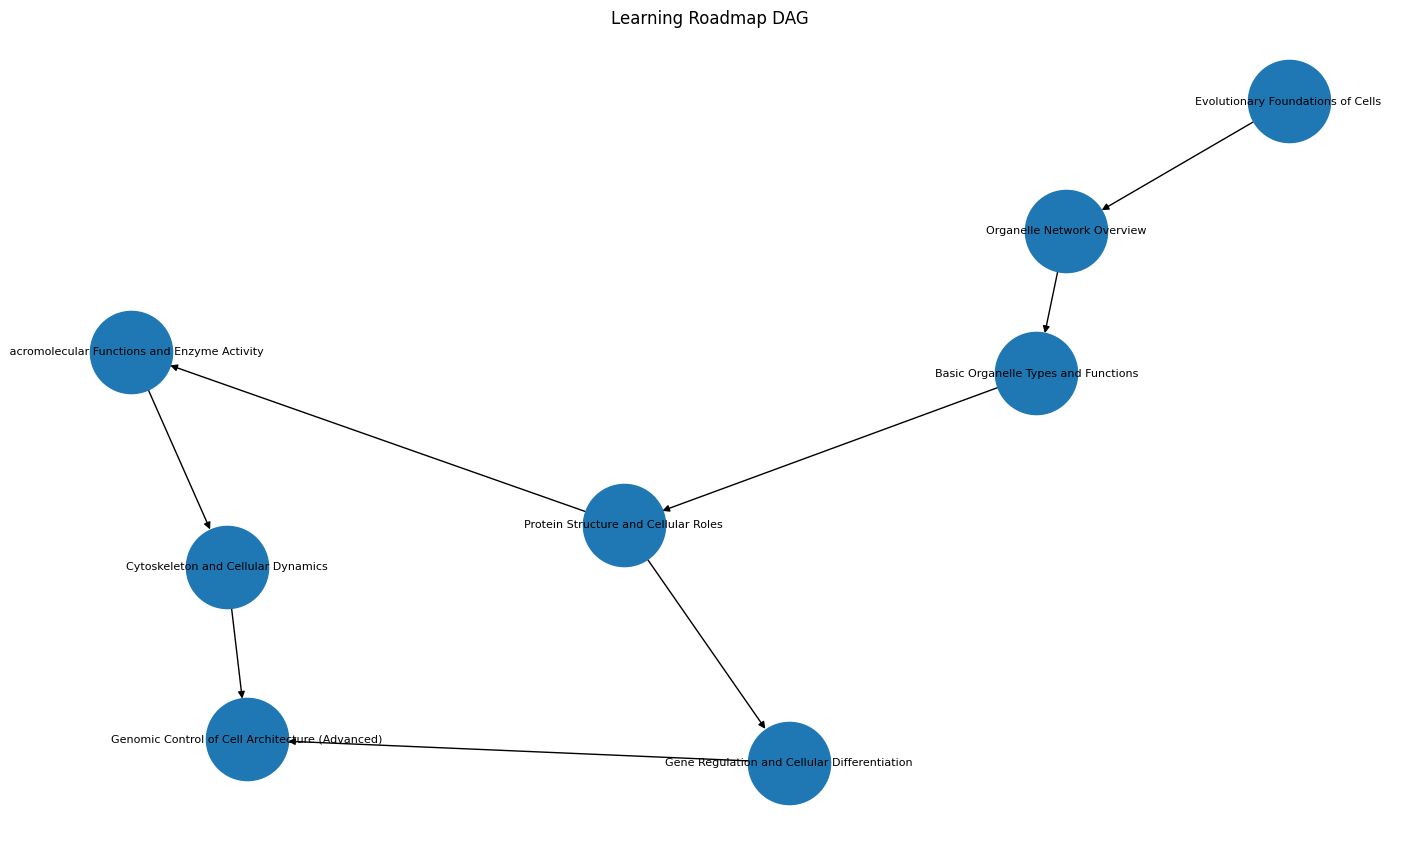

In [19]:
plt.figure(figsize=(14,8))

pos = nx.spring_layout(
    G,
    seed=42
)

labels = {}

for node, data in G.nodes(data=True):
    labels[node] = data["title"]

nx.draw(
    G,
    pos,
    with_labels=True,
    labels=labels,
    node_size=3500,
    arrows=True,
    font_size=8
)

plt.title("Learning Roadmap DAG")

plt.show()

In [20]:
selected_module = roadmap_json[0]

print(selected_module)

{'id': 1, 'title': 'Evolutionary Foundations of Cells', 'description': 'Explore the common ancestry of all cells and the evolutionary forces that shaped modern cellular organization.', 'learning_objectives': ['Explain why all modern cells share fundamental structures.', 'Describe the estimated time frame for the emergence of the first cellular ancestor.', 'Relate evolutionary concepts to the basic organization of a cell.'], 'difficulty': 1, 'cognitive_load': 1, 'estimated_minutes': 5, 'status': 'READY', 'prerequisites': []}


In [21]:
def retrieve_module_content(module, top_k=8):

    query = f"""
    {module['title']}

    Learning Objectives:
    {' '.join(module['learning_objectives'])}

    Description:
    {module['description']}
    """

    return retrieve(query, top_k)

In [22]:
module_chunks = retrieve_module_content(selected_module)

print("Retrieved Chunks:", len(module_chunks))

for chunk in module_chunks:
    print("="*70)
    print(chunk["content"][:250])

Retrieved Chunks: 8
Evolution offers a startling but compelling explanation of why present-day cells are so similar in their fundamentals: they have all inherited their genetic instructions from the same common ancestor. It is estimated that this ancestral cell existed 
All cells must be able to switch genes on and off in response to signals in their environment. But the cells of multicellular organisms have evolved this capacity to an extreme degree and in highly specialized ways to form organized arrays of differe
his correct folding requires the right environment—pH, ionic strength, metal ion concentrations, and so forth. Self-assembly therefore requires both information (pro- vided by the DNA sequence) and environment (the in- terior of a living cell), and i
This means that the changes in gene expression, which are often triggered by a transient signal, must be remembered by the cell. This phenomenon of _cell memory_ is a prerequisite for the creation of organized tissues and for t

In [23]:
def generate_script(module, retrieved_chunks):

    context = "\n\n".join([
        chunk["content"] for chunk in retrieved_chunks
    ])

    objectives = "\n".join(
        [f"- {obj}" for obj in module["learning_objectives"]]
    )

    prompt = f"""
You are an expert educator.

Generate a structured lecture script.

Module Title:
{module['title']}

Module Description:
{module['description']}

Learning Objectives:
{objectives}

Reference Material:
{context}

Instructions:

1. Begin with a short introduction.
2. Explain each concept clearly.
3. Use simple language.
4. Give real-life examples wherever possible.
5. Connect ideas logically.
6. End with a concise summary.
7. Mention one or two quick revision points.
8. Do NOT invent information outside the provided reference material.

Return only the lecture script.
"""

    response = client.chat.completions.create(
        model="openai/gpt-oss-120b",
        messages=[
            {
                "role":"user",
                "content":prompt
            }
        ],
        temperature=0.3
    )

    return response.choices[0].message.content

In [24]:
lecture_script = generate_script(
    selected_module,
    module_chunks
)

print(lecture_script)

**Lecture Script – Evolutionary Foundations of Cells**  

---

### 1. Introduction (2 min)  
- Welcome the class and state the purpose: *“Today we will discover why every cell on Earth looks alike at its core, and how evolution built the sophisticated cellular machines we see in plants, animals, and microbes.”*  
- Quote Dobzhansky to set the tone: *“Nothing in biology makes sense except in the light of evolution.”*  

---

### 2. All Modern Cells Share Fundamental Structures  

| Concept | What It Means | Why It Matters |
|---------|---------------|----------------|
| **Common ancestry** | All cells inherited their genetic instructions from a single early cell. | Explains the striking similarity of metabolic pathways, DNA‑based information, and basic organelles across bacteria, algae, fungi, and humans. |
| **Universal machinery** | The ancestral cell already possessed a prototype of the “universal machinery” – DNA, ribosomes, basic metabolic enzymes. | Provides the blueprint that lat

In [25]:
with open("lecture_script.txt", "w", encoding="utf-8") as f:
    f.write(lecture_script)

print("Lecture script saved successfully!")

Lecture script saved successfully!


In [26]:
def complete_module(roadmap_json, completed_module_id):
    for module in roadmap_json:
        if module["id"] == completed_module_id:
            module["status"] = "COMPLETED"

    for module in roadmap_json:

        if module["status"] == "LOCKED":

            prerequisites = module["prerequisites"]

            unlocked = True

            for prereq in prerequisites:

                prereq_module = next(
                    m for m in roadmap_json
                    if m["id"] == prereq
                )

                if prereq_module["status"] != "COMPLETED":
                    unlocked = False
                    break

            if unlocked:
                module["status"] = "READY"

    return roadmap_json

In [27]:
roadmap_json = complete_module(
    roadmap_json,
    completed_module_id=1
)

for module in roadmap_json:
    print(
        module["id"],
        module["title"],
        "→",
        module["status"]
    )

1 Evolutionary Foundations of Cells → COMPLETED
2 Organelle Network Overview → READY
3 Basic Organelle Types and Functions → LOCKED
4 Protein Structure and Cellular Roles → LOCKED
5 Macromolecular Functions and Enzyme Activity → LOCKED
6 Cytoskeleton and Cellular Dynamics → LOCKED
7 Gene Regulation and Cellular Differentiation → LOCKED
8 Genomic Control of Cell Architecture (Advanced) → LOCKED


In [28]:
while True:

    ready_modules = [
        module
        for module in roadmap_json
        if module["status"] == "READY"
    ]

    if not ready_modules:
        print("🎉 Learning roadmap completed!")
        break

    next_module = ready_modules[0]

    print(f"\nCurrent Module: {next_module['title']}")

    module_chunks = retrieve_module_content(next_module)

    lecture_script = generate_script(
        next_module,
        module_chunks
    )

    print("\nLecture Generated!\n")

    roadmap_json = complete_module(
        roadmap_json,
        next_module["id"]
    )


Current Module: Organelle Network Overview

Lecture Generated!


Current Module: Basic Organelle Types and Functions

Lecture Generated!


Current Module: Protein Structure and Cellular Roles

Lecture Generated!


Current Module: Macromolecular Functions and Enzyme Activity

Lecture Generated!


Current Module: Cytoskeleton and Cellular Dynamics

Lecture Generated!


Current Module: Gene Regulation and Cellular Differentiation

Lecture Generated!


Current Module: Genomic Control of Cell Architecture (Advanced)

Lecture Generated!

🎉 Learning roadmap completed!
